In [1]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!unzip -q '/content/drive/MyDrive/hackathon/unet_experiment/LEVIR-CD256.zip' -d /content/LEVIR-CD-real
print("Unzip complete.")

Unzip complete.


In [4]:
import os
for root, dirs, files in os.walk('/content/LEVIR-CD-real'):
    print(root, len(files), 'files')

/content/LEVIR-CD-real 0 files
/content/LEVIR-CD-real/LEVIR-CD256 0 files
/content/LEVIR-CD-real/LEVIR-CD256/label 10192 files
/content/LEVIR-CD-real/LEVIR-CD256/list 26 files
/content/LEVIR-CD-real/LEVIR-CD256/A 10192 files
/content/LEVIR-CD-real/LEVIR-CD256/B 10192 files


In [5]:
list_files = os.listdir('/content/LEVIR-CD-real/LEVIR-CD256/list')
print(list_files)

['100_train_supervised.txt', '10_train_supervised.txt', '30_train_supervised.txt', '10_train_unsupervised.txt', 'train(org).txt', '20_train_unsupervised.txt', '50_train_supervised.txt', 'test.txt', '40_train_supervised.txt', '5_train_unsupervised.txt', '70_train_supervised.txt', '30_train_unsupervised.txt', 'val.txt', '50_train_unsupervised.txt', 'trainval.txt', '20_train_supervised.txt', '60_train_unsupervised.txt', '60_train_supervised.txt', 'generate_semicd_splits.py', '100_train_unsupervised.txt', '40_train_unsupervised.txt', '80_train_supervised.txt', '70_train_unsupervised.txt', 'train.txt', '80_train_unsupervised.txt', '5_train_supervised.txt']


In [6]:
with open('/content/LEVIR-CD-real/LEVIR-CD256/list/train.txt') as f:
    lines = f.read().splitlines()
print(f"Number of training files: {len(lines)}")
print(lines[:5])

Number of training files: 7120
['train_100_10.png', 'train_100_11.png', 'train_100_12.png', 'train_100_13.png', 'train_100_14.png']


In [7]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import torch

class ChangeDataset(Dataset):
    def __init__(self, root, list_file, size=256):
        self.dir_a = os.path.join(root, 'A')
        self.dir_b = os.path.join(root, 'B')
        self.dir_label = os.path.join(root, 'label')
        with open(list_file) as f:
            self.files = f.read().splitlines()
        self.size = size

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        fname = self.files[idx]
        img_a = Image.open(os.path.join(self.dir_a, fname)).convert('RGB').resize((self.size, self.size))
        img_b = Image.open(os.path.join(self.dir_b, fname)).convert('RGB').resize((self.size, self.size))
        label = Image.open(os.path.join(self.dir_label, fname)).convert('L').resize((self.size, self.size))

        a = torch.from_numpy(np.array(img_a)).permute(2,0,1).float() / 255.0
        b = torch.from_numpy(np.array(img_b)).permute(2,0,1).float() / 255.0
        y = torch.from_numpy(np.array(label)).float().unsqueeze(0) / 255.0
        y = (y > 0.5).float()

        x = torch.cat([a, b], dim=0)
        return x, y

train_ds = ChangeDataset(
    root='/content/LEVIR-CD-real/LEVIR-CD256',
    list_file='/content/LEVIR-CD-real/LEVIR-CD256/list/train.txt',
    size=256
)
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
print(f"Training samples: {len(train_ds)}")

Training samples: 7120


In [8]:
x, y = train_ds[0]
print("Input shape:", x.shape)
print("Label shape:", y.shape)
print("Label unique values:", torch.unique(y))

Input shape: torch.Size([6, 256, 256])
Label shape: torch.Size([1, 256, 256])
Label unique values: tensor([0., 1.])


In [9]:
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_ch=6, out_ch=1):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(128, 256)
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)
        self.out = nn.Conv2d(32, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return torch.sigmoid(self.out(d1))

model = UNet(in_ch=6, out_ch=1).to(device)
print("Model created on:", device)

Model created on: cuda


In [10]:
import torch.optim as optim

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

num_epochs = 5
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        pred = model(x)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss/len(train_loader):.4f}")

Epoch 1/5, Loss: 0.1466
Epoch 2/5, Loss: 0.0700
Epoch 3/5, Loss: 0.0562
Epoch 4/5, Loss: 0.0479
Epoch 5/5, Loss: 0.0441


In [11]:
torch.save(model.state_dict(), '/content/drive/MyDrive/hackathon/unet_experiment/unet_model.pth')
print("Model saved to Drive.")

Model saved to Drive.


In [12]:
before_rgb = np.load('/content/drive/MyDrive/hackathon/before_rgb.npy')
after_rgb = np.load('/content/drive/MyDrive/hackathon/after_rgb.npy')
print(before_rgb.shape, after_rgb.shape)

(1114, 1670, 3) (1114, 1670, 3)


In [13]:
import cv2

def prep_for_unet(img, size=256):
    img_resized = cv2.resize(img, (size, size))
    img_resized = np.clip(img_resized, 0, 1)
    tensor = torch.from_numpy(img_resized).permute(2,0,1).float().unsqueeze(0)
    return tensor

before_tensor = prep_for_unet(before_rgb).to(device)
after_tensor = prep_for_unet(after_rgb).to(device)

model.eval()
with torch.no_grad():
    x = torch.cat([before_tensor, after_tensor], dim=1)
    pred_mask = model(x)
    pred_mask = pred_mask.squeeze().cpu().numpy()

print("Prediction shape:", pred_mask.shape)
print("Prediction range:", pred_mask.min(), pred_mask.max())

Prediction shape: (256, 256)
Prediction range: 0.00012108542 0.7418774


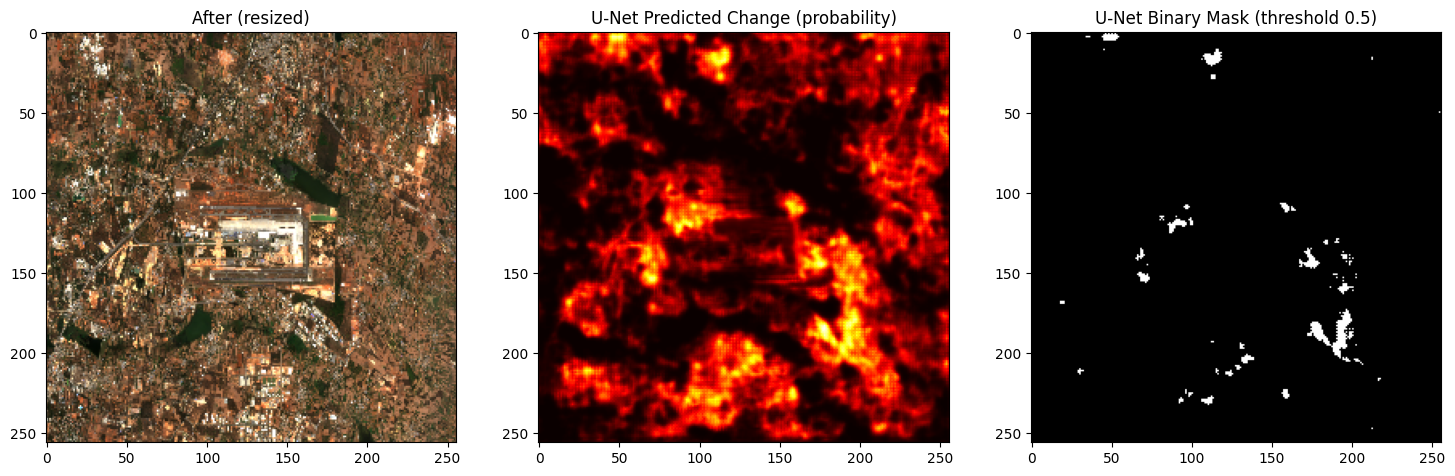

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18,6))
axes[0].imshow(cv2.resize(after_rgb, (256,256)))
axes[0].set_title('After (resized)')
axes[1].imshow(pred_mask, cmap='hot')
axes[1].set_title('U-Net Predicted Change (probability)')
axes[2].imshow((pred_mask > 0.5).astype(np.uint8), cmap='gray')
axes[2].set_title('U-Net Binary Mask (threshold 0.5)')
plt.show()

In [15]:
def tiled_inference(before_img, after_img, model, tile_size=256, stride=128):
    h, w, _ = before_img.shape
    pred_sum = np.zeros((h, w), dtype=np.float32)
    pred_count = np.zeros((h, w), dtype=np.float32)

    model.eval()
    with torch.no_grad():
        for y in range(0, h - tile_size + 1, stride):
            for x in range(0, w - tile_size + 1, stride):
                tile_before = before_img[y:y+tile_size, x:x+tile_size]
                tile_after = after_img[y:y+tile_size, x:x+tile_size]

                t_before = torch.from_numpy(tile_before).permute(2,0,1).float().unsqueeze(0).to(device)
                t_after = torch.from_numpy(tile_after).permute(2,0,1).float().unsqueeze(0).to(device)
                inp = torch.cat([t_before, t_after], dim=1)

                pred = model(inp).squeeze().cpu().numpy()
                pred_sum[y:y+tile_size, x:x+tile_size] += pred
                pred_count[y:y+tile_size, x:x+tile_size] += 1

    pred_count[pred_count == 0] = 1  # avoid divide-by-zero at edges
    return pred_sum / pred_count

In [16]:
pred_mask_full = tiled_inference(before_rgb, after_rgb, model, tile_size=256, stride=128)
print("Full-res prediction shape:", pred_mask_full.shape)
print("Prediction range:", pred_mask_full.min(), pred_mask_full.max())

Full-res prediction shape: (1114, 1670)
Prediction range: 0.0 0.9523396


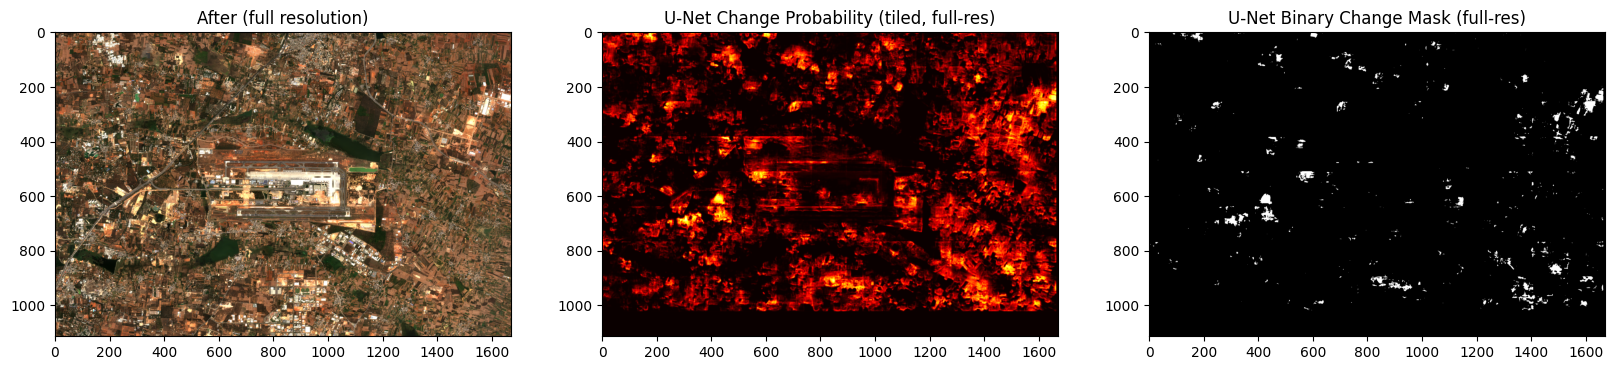

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(20,7))
axes[0].imshow(after_rgb)
axes[0].set_title('After (full resolution)')
axes[1].imshow(pred_mask_full, cmap='hot')
axes[1].set_title('U-Net Change Probability (tiled, full-res)')
axes[2].imshow((pred_mask_full > 0.5).astype(np.uint8), cmap='gray')
axes[2].set_title('U-Net Binary Change Mask (full-res)')
plt.show()

In [18]:
pred_mask_smooth = tiled_inference(before_rgb, after_rgb, model, tile_size=256, stride=64)

In [19]:
import rasterio.features
with rasterio.open('/content/drive/MyDrive/hackathon/blr_after.tif') as src:
    transform = src.transform
    crs = src.crs

In [20]:
import rasterio
import rasterio.features
import geopandas as gpd
from shapely.geometry import shape

In [21]:
unet_binary = (pred_mask_full > 0.5).astype(np.uint8)
kernel = np.ones((3,3), np.uint8)
unet_clean = cv2.morphologyEx(unet_binary, cv2.MORPH_OPEN, kernel)
unet_clean = cv2.morphologyEx(unet_clean, cv2.MORPH_CLOSE, kernel)

shapes_gen = rasterio.features.shapes(unet_clean, transform=transform)
unet_polygons = [shape(geom) for geom, val in shapes_gen if val == 1]
gdf_unet = gpd.GeoDataFrame(geometry=unet_polygons, crs=crs)
print(f"U-Net polygons found: {len(gdf_unet)}")

U-Net polygons found: 267


In [22]:
gdf_unet.to_file('/content/drive/MyDrive/hackathon/unet_experiment/unet_change_polygons.geojson', driver='GeoJSON')
print("Saved U-Net polygons.")

Saved U-Net polygons.


In [23]:
gdf_unet_m = gdf_unet.to_crs(epsg=32643)
gdf_unet['area_sqm'] = gdf_unet_m.geometry.area
print(gdf_unet['area_sqm'].describe())

count       267.000000
mean       9790.136711
std       20216.263900
min         581.234368
25%        1259.816967
50%        2810.142040
75%        7947.483279
max      153687.943944
Name: area_sqm, dtype: float64


In [24]:
gdf_changes_filtered = gpd.read_file('/content/drive/MyDrive/hackathon/priority_alerts.csv')

In [25]:
gdf_changes_filtered = gpd.read_file('/content/drive/MyDrive/hackathon/ndvi_change_polygons.geojson')
print(f"Loaded NDVI polygons: {len(gdf_changes_filtered)}")

Loaded NDVI polygons: 301


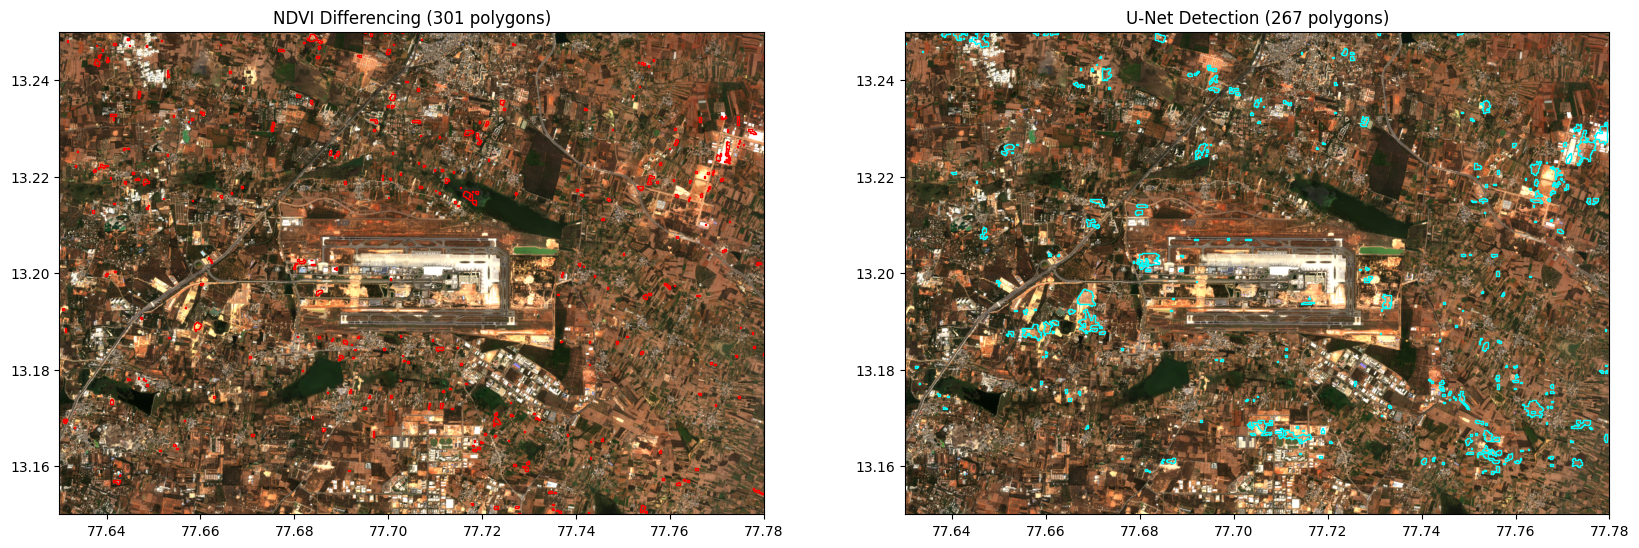

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(20,10))

extent = [transform[2], transform[2]+transform[0]*after_rgb.shape[1],
          transform[5]+transform[4]*after_rgb.shape[0], transform[5]]

axes[0].imshow(after_rgb, extent=extent)
gdf_changes_filtered.plot(ax=axes[0], facecolor='none', edgecolor='red', linewidth=1)
axes[0].set_xlim(extent[0], extent[1])
axes[0].set_ylim(extent[2], extent[3])
axes[0].set_title(f'NDVI Differencing ({len(gdf_changes_filtered)} polygons)')

axes[1].imshow(after_rgb, extent=extent)
gdf_unet.plot(ax=axes[1], facecolor='none', edgecolor='cyan', linewidth=1)
axes[1].set_xlim(extent[0], extent[1])
axes[1].set_ylim(extent[2], extent[3])
axes[1].set_title(f'U-Net Detection ({len(gdf_unet)} polygons)')

plt.show()

In [27]:
print(gdf_changes_filtered.columns.tolist())
print(gdf_changes_filtered['area_sqm'].describe())

['area_sqm', 'severity', 'change_id', 'final_severity', 'geometry']
count      301.000000
mean      3012.273848
std       3861.172226
min        581.550075
25%        872.306066
50%       1744.607827
75%       3295.211827
max      38371.565405
Name: area_sqm, dtype: float64


In [28]:
val_ds = ChangeDataset(
    root='/content/LEVIR-CD-real/LEVIR-CD256',
    list_file='/content/LEVIR-CD-real/LEVIR-CD256/list/val.txt',
    size=256
)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)
print(f"Validation samples: {len(val_ds)}")

Validation samples: 1024


In [29]:
def compute_metrics(model, loader, threshold=0.5):
    model.eval()
    tp, fp, fn, tn = 0, 0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            pred_binary = (pred > threshold).float()

            tp += ((pred_binary == 1) & (y == 1)).sum().item()
            fp += ((pred_binary == 1) & (y == 0)).sum().item()
            fn += ((pred_binary == 0) & (y == 1)).sum().item()
            tn += ((pred_binary == 0) & (y == 0)).sum().item()

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)
    accuracy = (tp + tn) / (tp + fp + fn + tn + 1e-8)

    return {
        'Precision': precision, 'Recall': recall,
        'F1 Score': f1, 'IoU': iou, 'Pixel Accuracy': accuracy
    }

metrics = compute_metrics(model, val_loader)
for k, v in metrics.items():
    print(f"{k}: {v:.4f}")

Precision: 0.8883
Recall: 0.7795
F1 Score: 0.8303
IoU: 0.7099
Pixel Accuracy: 0.9866
